# Lab 4: Regression Analysis and Regularization

**Name:** Aashish Shrestha

**Course:** Advance Big Data and Data Mining (MSCS-634)

**Lab Assignment:** Lab 4 &ndash; Regression and Regularization 


## What this lab is about

In this lab I build and compare several regression models on the **Diabetes dataset** from
scikit-learn. Regression is used to predict a number, not a class. Here the number is a score that
shows how much the disease moved forward one year later.

I go step by step:

1. Simple Linear Regression (one feature).
2. Multiple Regression (all features).
3. Polynomial Regression (and I show how a high degree causes overfitting).
4. Ridge and Lasso Regression (these add a penalty to stop overfitting).
5. A final comparison of every model.

To judge the models I use four numbers:

- **MAE** (Mean Absolute Error): the average size of the error. Lower is better.
- **MSE** (Mean Squared Error): like MAE but it punishes big errors more. Lower is better.
- **RMSE** (Root Mean Squared Error): the square root of MSE, so it is back in the same unit as the
  target. Lower is better.
- **R2** (R-squared): the part of the target that the model can explain, from 0 to 1. Higher is
  better. A value near 0 means the model is weak.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

%matplotlib inline
plt.rcParams["figure.figsize"] = (8, 5)

# One helper so every model is scored the same way
def score_model(name, y_true, y_pred, show=True):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    if show:
        print(f"{name}")
        print(f"  MAE  = {mae:.2f}")
        print(f"  MSE  = {mse:.2f}")
        print(f"  RMSE = {rmse:.2f}")
        print(f"  R2   = {r2:.4f}")
    return {"Model": name, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

## Step 1: Data Preparation

I load the Diabetes dataset and look at it first.


In [2]:
diabetes = load_diabetes()
X = diabetes.data
y = diabetes.target
feature_names = diabetes.feature_names

df = pd.DataFrame(X, columns=feature_names)
df["target"] = y

print("Number of rows (patients):", X.shape[0])
print("Number of features:", X.shape[1])
print("Feature names:", feature_names)
print("Target: min =", y.min(), " max =", y.max(), " mean =", round(y.mean(), 1))
df.head()

Number of rows (patients): 442
Number of features: 10
Feature names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Target: min = 25.0  max = 346.0  mean = 152.1


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


One important point about this dataset: scikit-learn already scaled every feature. So each column has a mean near 0 and small values. This is why I do not need to standardize again. Also I check for missing values.

In [3]:
# Check scaling (means should be near 0) and missing values
print("Mean of each feature (first row) - should be about 0:")
print(np.round(df[feature_names].mean().values, 4))
print()
print("Total missing values in the data:", int(df.isna().sum().sum()))

Mean of each feature (first row) - should be about 0:
[-0.  0. -0. -0. -0.  0. -0. -0.  0.  0.]

Total missing values in the data: 0


No missing values, so no cleaning is needed. Next I look at which feature is most related to the target. A value close to 1 or -1 means a strong relation.

bmi    0.586
s5     0.566
bp     0.441
s4     0.430
s6     0.382
s1     0.212
age    0.188
s2     0.174
sex    0.043
s3    -0.395
Name: target, dtype: float64


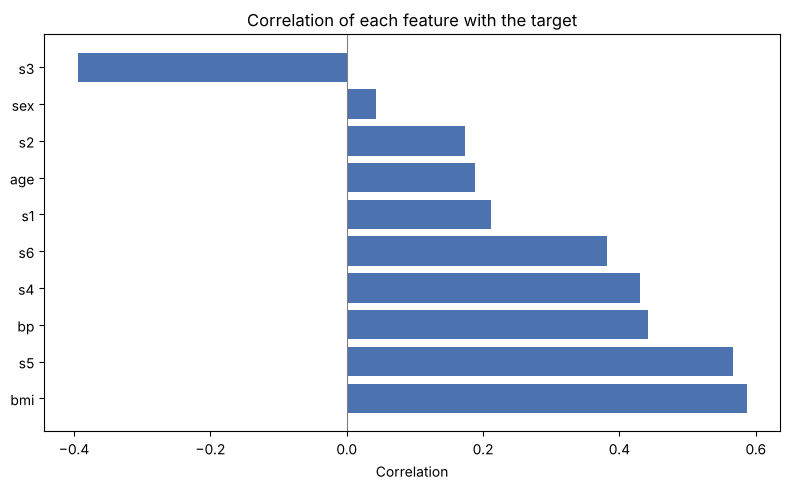

In [4]:
# Correlation of each feature with the target
corr = df.corr()["target"].drop("target").sort_values(ascending=False)
print(corr.round(3))

plt.barh(corr.index, corr.values, color="#4C72B0")
plt.axvline(0, color="grey", linewidth=0.8)
plt.title("Correlation of each feature with the target")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()

The strongest feature is **bmi** (body mass index), then **s5**. So for the simple model with only one feature, I will use bmi.

## Step 2: Simple Linear Regression (one feature)

Here I use only **bmi** to predict the target. I split the data into 80% for training and 20% for
testing, train the model, and then check the four scores on the test part.


In [5]:
# Use only the bmi column
X_bmi = X[:, feature_names.index("bmi")].reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X_bmi, y, test_size=0.2, random_state=42)

lin_simple = LinearRegression()
lin_simple.fit(X_train, y_train)
y_pred_simple = lin_simple.predict(X_test)

res_simple = score_model("Simple Linear Regression (bmi only)", y_test, y_pred_simple)

Simple Linear Regression (bmi only)
  MAE  = 52.26
  MSE  = 4061.83
  RMSE = 63.73
  R2   = 0.2334


Now I draw the test points and the line that the model learned.

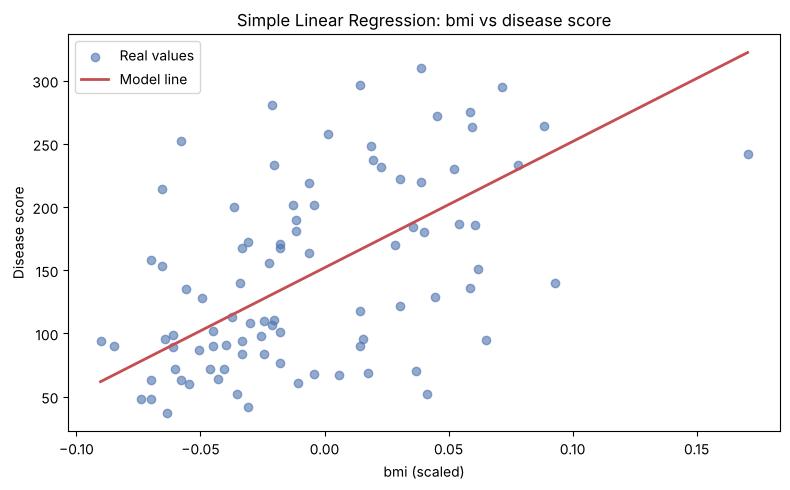

In [6]:
# Plot: real test points and the regression line
order = np.argsort(X_test.ravel())
plt.scatter(X_test, y_test, color="#4C72B0", alpha=0.6, label="Real values")
plt.plot(X_test[order], y_pred_simple[order], color="#C44E52", linewidth=2, label="Model line")
plt.title("Simple Linear Regression: bmi vs disease score")
plt.xlabel("bmi (scaled)")
plt.ylabel("Disease score")
plt.legend()
plt.tight_layout()
plt.show()

The line goes up, so a higher bmi means a higher disease score. But the points are spread far from the line, and the R2 is low (about 0.23). This tells me one feature alone can not explain the target well.

## Step 3: Multiple Regression (all features)

Now I use all 10 features together. More useful information should give a better model.


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

lin_multi = LinearRegression()
lin_multi.fit(X_train, y_train)
y_pred_multi = lin_multi.predict(X_test)

res_multi = score_model("Multiple Linear Regression (all 10 features)", y_test, y_pred_multi)

Multiple Linear Regression (all 10 features)
  MAE  = 42.79
  MSE  = 2900.19
  RMSE = 53.85
  R2   = 0.4526


A good way to see a multiple-feature model is to plot the predicted value against the real value. If the model is perfect, all points sit on the diagonal line.

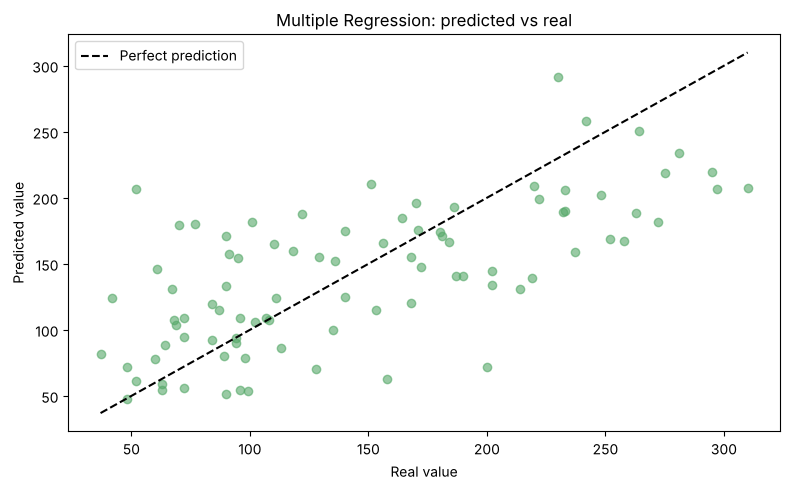

In [8]:
plt.scatter(y_test, y_pred_multi, color="#55A868", alpha=0.6)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, color="black", linestyle="--", label="Perfect prediction")
plt.title("Multiple Regression: predicted vs real")
plt.xlabel("Real value")
plt.ylabel("Predicted value")
plt.legend()
plt.tight_layout()
plt.show()

The R2 jumped from about 0.23 to about 0.45, and the RMSE dropped a lot (from about 64 to about 54). So using all features is clearly much better than using only bmi. The points now sit closer to the diagonal line.

## Step 4: Polynomial Regression

Polynomial regression adds powers and products of the features (like bmi squared, bmi times bp, and
so on). This lets the model bend and fit curves. But if the degree is too high, the model starts to
memorize the training data instead of learning the real pattern. This is called **overfitting**.

To show this clearly, I train the model with degree 1, 2, 3, and 4, and I compare the R2 on the
training data with the R2 on the test data.


In [9]:
degrees = [1, 2, 3, 4]
train_r2, test_r2, n_features = [], [], []

for deg in degrees:
    poly_model = make_pipeline(PolynomialFeatures(deg, include_bias=False), LinearRegression())
    poly_model.fit(X_train, y_train)
    r2_tr = r2_score(y_train, poly_model.predict(X_train))
    r2_te = r2_score(y_test, poly_model.predict(X_test))
    nf = poly_model.named_steps["polynomialfeatures"].n_output_features_
    train_r2.append(r2_tr); test_r2.append(r2_te); n_features.append(nf)
    print(f"Degree {deg}: {nf:4d} features | train R2 = {r2_tr:.3f} | test R2 = {r2_te:.3f}")

# save degree-2 result for the final comparison table
res_poly = score_model("Polynomial Regression (degree 2)", y_test,
                        make_pipeline(PolynomialFeatures(2, include_bias=False),
                                      LinearRegression()).fit(X_train, y_train).predict(X_test),
                        show=False)

Degree 1:   10 features | train R2 = 0.528 | test R2 = 0.453
Degree 2:   65 features | train R2 = 0.606 | test R2 = 0.416
Degree 3:  285 features | train R2 = 0.857 | test R2 = -5.212
Degree 4: 1000 features | train R2 = 1.000 | test R2 = -26.728


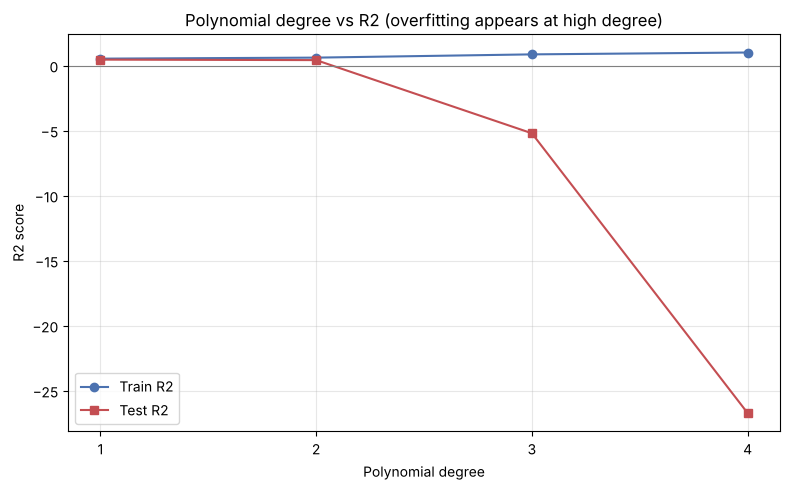

In [10]:
# Plot train vs test R2 to show overfitting
plt.plot(degrees, train_r2, marker="o", label="Train R2", color="#4C72B0")
plt.plot(degrees, test_r2, marker="s", label="Test R2", color="#C44E52")
plt.axhline(0, color="grey", linewidth=0.8)
plt.title("Polynomial degree vs R2 (overfitting appears at high degree)")
plt.xlabel("Polynomial degree")
plt.ylabel("R2 score")
plt.xticks(degrees)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

This plot shows the overfitting story very well:

- **Degree 1** is the same as the normal multiple model. Train and test R2 are close, so it is
  balanced.
- **Degree 2** fits the training data a bit better, but the test R2 already starts to drop. The
  model is beginning to overfit.
- **Degree 3 and 4** fit the training data almost perfectly (degree 4 reaches train R2 = 1.0), but
  the test R2 becomes very negative. This means the model memorized the training points and fails
  badly on new data. The number of features also explodes (1000 features at degree 4 from only 10
  original features).

So a higher degree is not always better. After a point it only causes overfitting.


## Step 5: Regularization with Ridge and Lasso

Ridge and Lasso are linear models with an extra penalty on the size of the coefficients. This
penalty keeps the weights small, which helps the model stay simple and avoid overfitting. The
penalty strength is controlled by **alpha**:

- Small alpha = almost no penalty (close to the normal linear model).
- Large alpha = strong penalty (weights shrink a lot, the model can become too simple).

The difference between the two:

- **Ridge** shrinks all weights towards zero but keeps all features.
- **Lasso** can push some weights exactly to zero, so it removes weak features by itself. This is
  useful for feature selection.


In [11]:
# Ridge across several alpha values
print("RIDGE")
ridge_rows = []
for a in [0.1, 1.0, 10.0, 100.0]:
    m = Ridge(alpha=a).fit(X_train, y_train)
    r = score_model(f"Ridge (alpha={a})", y_test, m.predict(X_test), show=False)
    ridge_rows.append({"alpha": a, "RMSE": round(r["RMSE"],2), "R2": round(r["R2"],4)})
    print(f"  alpha={a:6}: RMSE={r['RMSE']:.2f}  R2={r['R2']:.4f}")

# keep the best Ridge for the final table
best_ridge = Ridge(alpha=0.1).fit(X_train, y_train)
res_ridge = score_model("Ridge Regression (alpha=0.1)", y_test, best_ridge.predict(X_test), show=False)

RIDGE
  alpha=   0.1: RMSE=53.45  R2=0.4609
  alpha=   1.0: RMSE=55.47  R2=0.4192
  alpha=  10.0: RMSE=66.66  R2=0.1612
  alpha= 100.0: RMSE=72.34  R2=0.0122


In [12]:
# Lasso across several alpha values (also count how many features stay)
print("LASSO")
lasso_rows = []
for a in [0.01, 0.1, 1.0, 10.0]:
    m = Lasso(alpha=a, max_iter=10000).fit(X_train, y_train)
    r = score_model(f"Lasso (alpha={a})", y_test, m.predict(X_test), show=False)
    kept = int(np.sum(m.coef_ != 0))
    lasso_rows.append({"alpha": a, "RMSE": round(r["RMSE"],2), "R2": round(r["R2"],4), "features_kept": kept})
    print(f"  alpha={a:6}: RMSE={r['RMSE']:.2f}  R2={r['R2']:.4f}  features kept={kept}/10")

# keep the best Lasso for the final table
best_lasso = Lasso(alpha=0.1, max_iter=10000).fit(X_train, y_train)
res_lasso = score_model("Lasso Regression (alpha=0.1)", y_test, best_lasso.predict(X_test), show=False)

LASSO
  alpha=  0.01: RMSE=53.65  R2=0.4567  features kept=10/10
  alpha=   0.1: RMSE=52.90  R2=0.4719  features kept=7/10
  alpha=   1.0: RMSE=58.34  R2=0.3576  features kept=3/10
  alpha=  10.0: RMSE=73.22  R2=-0.0120  features kept=0/10


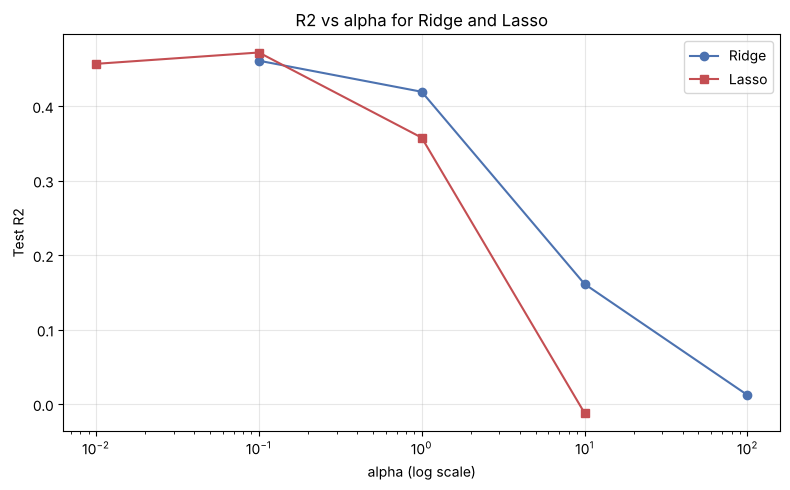

In [13]:
# Plot R2 vs alpha for both, on a log scale for alpha
r_alphas = [0.1, 1.0, 10.0, 100.0]
r_scores = [r["R2"] for r in ridge_rows]
l_alphas = [0.01, 0.1, 1.0, 10.0]
l_scores = [r["R2"] for r in lasso_rows]

plt.plot(r_alphas, r_scores, marker="o", label="Ridge", color="#4C72B0")
plt.plot(l_alphas, l_scores, marker="s", label="Lasso", color="#C44E52")
plt.xscale("log")
plt.title("R2 vs alpha for Ridge and Lasso")
plt.xlabel("alpha (log scale)")
plt.ylabel("Test R2")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

What the alpha values show:

- When alpha is small, both Ridge and Lasso behave almost like the normal multiple model.
- When alpha grows too large, the penalty becomes too strong and the R2 drops. For Lasso with
  alpha = 10, every weight becomes zero, so the model predicts only the average and the R2 goes
  below 0.
- The best result came from a **small** alpha. Lasso with alpha = 0.1 was the best of all models
  (R2 about 0.47), and it did this while keeping only 7 features out of 10. So it threw away 3 weak
  features and still improved. Ridge with alpha = 0.1 was also a small improvement over the plain
  model.


## Step 6: Model Comparison and Analysis

Now I put every model together in one table and one chart to compare them.


In [14]:
summary = pd.DataFrame([res_simple, res_multi, res_poly, res_ridge, res_lasso])
summary = summary.round({"MAE":2, "MSE":2, "RMSE":2, "R2":4})
summary

,Model,MAE,MSE,RMSE,R2
0,Simple Linear Regression (bmi only),52.26,4061.83,63.73,0.2334
1,Multiple Linear Regression (all 10 features),42.79,2900.19,53.85,0.4526
2,Polynomial Regression (degree 2),43.58,3096.03,55.64,0.4156
3,Ridge Regression (alpha=0.1),43.00,2856.49,53.45,0.4609
4,Lasso Regression (alpha=0.1),42.85,2798.19,52.90,0.4719


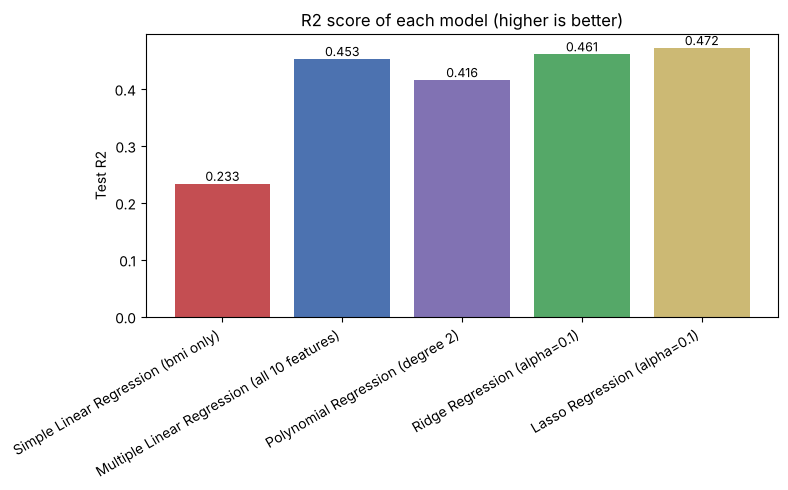

In [15]:
# Bar chart of R2 for every model
plt.bar(summary["Model"], summary["R2"], color=["#C44E52","#4C72B0","#8172B3","#55A868","#CCB974"])
plt.title("R2 score of each model (higher is better)")
plt.ylabel("Test R2")
plt.xticks(rotation=30, ha="right")
for i, v in enumerate(summary["R2"]):
    plt.text(i, v + 0.005, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

### Key observations

**Model performance ** The simple model with only bmi was the weakest (R2 about 0.23). Moving
to all 10 features almost doubled the R2 to about 0.45. Ridge and Lasso with a small alpha did a
little better, and Lasso (alpha 0.1) was the best overall at about 0.47.

**Models handled overfitting** Polynomial regression showed the overfitting problem clearly.
At degree 3 and 4 the model fit the training data almost perfectly but failed completely on the test
data (negative R2). Ridge and Lasso are the models that fight overfitting. Their penalty keeps the
weights small, so they stay stable and do not chase noise in the training data. Lasso goes further
and removes weak features on its own.

**Insights about the Diabetes dataset.** This is a hard dataset to predict. Even the best model only
explains about 47% of the target, so the health score depends on many things that these 10
measurements do not fully capture. The two most useful features are bmi and s5. The data is already
scaled and has no missing values, so most of the work is about choosing the right model and the
right amount of regularization, not about cleaning. Because the number of features is small (10),
a simple linear model is already quite good, and heavy methods like high-degree polynomials only
make things worse here.
